# 2.2.2. Bài làm mẫu - Bài toán 1: SVM trên Iris

Theo các bước của tài liệu: nạp dữ liệu → chuẩn bị train/test → xây SVM → đánh giá → chọn kernel. Dùng data/Iris.csv đã cung cấp. Chọn kernel bằng CV trên train thay vì thử trực tiếp trên test như đoạn minh họa trong PDF, để giữ test độc lập.

## Nhiệm vụ 1. Xây dựng SVM phân loại hoa diên vĩ

### Bước 1. Nạp thư viện và dữ liệu

In [1]:
from pathlib import Path
from time import perf_counter
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn import svm, datasets
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.exceptions import ConvergenceWarning

get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams['figure.dpi'] = 120
RANDOM_STATE = 101
# Bao loi neu bo giai chua hoi tu, tranh su dung ket qua huan luyen dang do.
warnings.filterwarnings('error', category=ConvergenceWarning)


lab_candidates = []
for parent in [Path.cwd(), *Path.cwd().parents]:
    lab_candidates.extend([parent, parent / 'Lab05' / '2.2. Giai_Thuat2'])
# Duong dan du an duoc chi dinh; dung khi mo ban notebook tu thu muc outputs.
lab_candidates.append(Path(r'D:\SGU_HocMay_2026-2027\Lab05\2.2. Giai_Thuat2'))
LAB_DIR = next((p for p in lab_candidates if (p / 'data' / 'Iris.csv').is_file()), None)
if LAB_DIR is None:
    raise FileNotFoundError('Chua tim thay thu muc data cua Lab05/2.2. Giai_Thuat2.')
DATA_DIR = LAB_DIR / 'data'
print('Thu muc du lieu:', DATA_DIR)

Thu muc du lieu: D:\SGU_HocMay_2026-2027\Lab05\2.2. Giai_Thuat2\data


Du lieu: (150, 6) | Bo cot Id vi la dinh danh


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000,150.000,150.000,150.000
mean,5.843,3.054,3.759,1.199
std,0.828,0.434,1.764,0.763
min,4.300,2.000,1.000,0.100
25%,5.100,2.800,1.600,0.300
50%,5.800,3.000,4.350,1.300
75%,6.400,3.300,5.100,1.800
max,7.900,4.400,6.900,2.500


Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

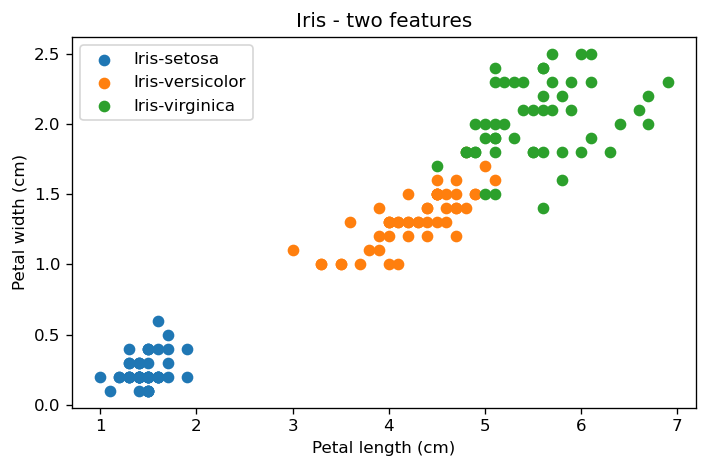

In [2]:
df=pd.read_csv(DATA_DIR/'Iris.csv')
feature_columns=['SepalLengthCm','SepalWidthCm','PetalLengthCm','PetalWidthCm']
assert not df[feature_columns+['Species']].isna().any().any()
X=df[feature_columns].copy()
y=df['Species'].copy()
CLASS_NAMES=sorted(y.unique())
RESULT_SLUG='Bai_mau_Iris'
SCORING='accuracy'
print('Du lieu:',df.shape,'| Bo cot Id vi la dinh danh')
display(df.head())
display(X.describe().round(3))
display(y.value_counts())
fig,ax=plt.subplots(figsize=(6,4))
for label in CLASS_NAMES:
    rows=y==label
    ax.scatter(X.loc[rows,'PetalLengthCm'],X.loc[rows,'PetalWidthCm'],label=label)
ax.set(xlabel='Petal length (cm)',ylabel='Petal width (cm)',title='Iris - two features')
ax.legend()
plt.tight_layout()
plt.show()

### Bước 2. Chuẩn bị train/test và tạo SVM

Chia 80:20, seed 101 và stratify theo nhãn. Loại Id, giữ 4 số đo làm đặc trưng. Pipeline chuẩn hóa chỉ trên train; SVC baseline dùng RBF, C=1. Tập test chỉ được đọc để chấm mô hình sau khi chọn kernel bằng CV.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
assert set(X_train.index).isdisjoint(X_test.index)
print('Train:', X_train.shape, '| Test:', X_test.shape)
display(pd.DataFrame({'train': y_train.value_counts(), 'test': y_test.value_counts()}).sort_index())
cv_splitter = StratifiedKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)

Train: (120, 4) | Test: (30, 4)


,train,test
Species,,
Iris-setosa,40,10
Iris-versicolor,40,10
Iris-virginica,40,10


In [4]:
baseline=Pipeline([('scale',StandardScaler()),('svc',svm.SVC(kernel='rbf',C=1,gamma='scale'))])

t0 = perf_counter()
baseline.fit(X_train, y_train)
print('Train accuracy (baseline):', round(baseline.score(X_train, y_train), 4))
print('Thoi gian fit baseline:', round(perf_counter() - t0, 2), 'giay')

Train accuracy (baseline): 0.975
Thoi gian fit baseline: 0.0 giay


### Bước 3. Tìm kernel và C bằng GridSearchCV

Khảo sát linear, poly, rbf, sigmoid với C=0,1; 1; 10. Đây là tối ưu trong lưới đã chọn, không bảo đảm tối ưu toàn cục. mean_test_score trong CV là validation của từng fold, không phải test cuối.

Scoring: accuracy
Baseline mean CV: 0.9667
Tham so tot nhat: {'svc__C': 10, 'svc__kernel': 'linear'}
Mean CV tot nhat: 0.975
Thoi gian tim kiem: 0.23 giay


,params,mean_train_score,mean_test_score,std_test_score,mean_fit_time
8,"{'svc__C': 10, 'svc__kernel': 'linear'}",0.983333,0.975000,0.014434,0.001791
4,"{'svc__C': 1, 'svc__kernel': 'linear'}",0.983333,0.966667,0.033333,0.001652
6,"{'svc__C': 1, 'svc__kernel': 'rbf'}",0.969444,0.966667,0.023570,0.001713
9,"{'svc__C': 10, 'svc__kernel': 'poly'}",0.972222,0.958333,0.027639,0.001776
10,"{'svc__C': 10, 'svc__kernel': 'rbf'}",0.988889,0.958333,0.014434,0.001811
0,"{'svc__C': 0.1, 'svc__kernel': 'linear'}",0.955556,0.958333,0.027639,0.001793
5,"{'svc__C': 1, 'svc__kernel': 'poly'}",0.922222,0.900000,0.052705,0.001663
7,"{'svc__C': 1, 'svc__kernel': 'sigmoid'}",0.894444,0.891667,0.036324,0.001769
2,"{'svc__C': 0.1, 'svc__kernel': 'rbf'}",0.900000,0.883333,0.037268,0.001998
3,"{'svc__C': 0.1, 'svc__kernel': 'sigmoid'}",0.866667,0.858333,0.027639,0.001793


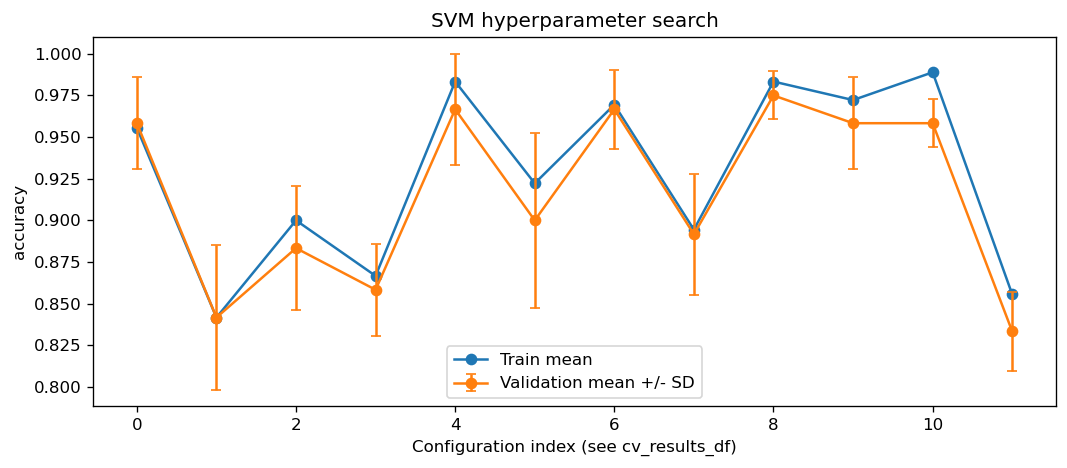

In [5]:
param_grid={'svc__kernel':['linear','poly','rbf','sigmoid'],'svc__C':[0.1,1,10]}

# Khong dung test de chon kernel hay tham so.
t0 = perf_counter()
baseline_cv_scores = cross_val_score(
    baseline, X_train, y_train, cv=cv_splitter, scoring=SCORING, n_jobs=1, error_score='raise'
)
search = GridSearchCV(
    clone(baseline), param_grid=param_grid, scoring=SCORING, cv=cv_splitter,
    refit=True, return_train_score=True, error_score='raise', n_jobs=1
)
search.fit(X_train, y_train)
best_svm = search.best_estimator_
cv_results_df = pd.DataFrame(search.cv_results_)
print('Scoring:', SCORING)
print('Baseline mean CV:', round(baseline_cv_scores.mean(), 4))
print('Tham so tot nhat:', search.best_params_)
print('Mean CV tot nhat:', round(search.best_score_, 4))
print('Thoi gian tim kiem:', round(perf_counter()-t0, 2), 'giay')
display(cv_results_df[['params', 'mean_train_score', 'mean_test_score',
                       'std_test_score', 'mean_fit_time']].sort_values('mean_test_score', ascending=False).head(12))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(np.arange(len(cv_results_df)), cv_results_df['mean_train_score'], 'o-', label='Train mean')
ax.errorbar(np.arange(len(cv_results_df)), cv_results_df['mean_test_score'],
            yerr=cv_results_df['std_test_score'], fmt='o-', capsize=3, label='Validation mean +/- SD')
ax.set(xlabel='Configuration index (see cv_results_df)', ylabel=SCORING, title='SVM hyperparameter search')
ax.legend()
plt.tight_layout()
plt.show()

### Bước 4. Đánh giá accuracy và confusion matrix

Đánh giá baseline và cấu hình đã chốt trên cùng 30 mẫu test. Không điều chỉnh lại tham số bằng kết quả test. Kết quả có thể khác con số minh họa của PDF do cách chia phân tầng, scaling và chọn kernel bằng CV.


SVM baseline
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30


SVM tuned
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



,Train accuracy,CV score,Test accuracy,Test balanced accuracy,Test precision macro,Test recall macro,Test F1 macro
Model,,,,,,,
SVM baseline,0.975,0.9667,0.9667,0.9667,0.9697,0.9667,0.9666
SVM tuned,0.975,0.9750,0.9667,0.9667,0.9697,0.9667,0.9666


Accuracy neu luon doan lop pho bien: 0.3333


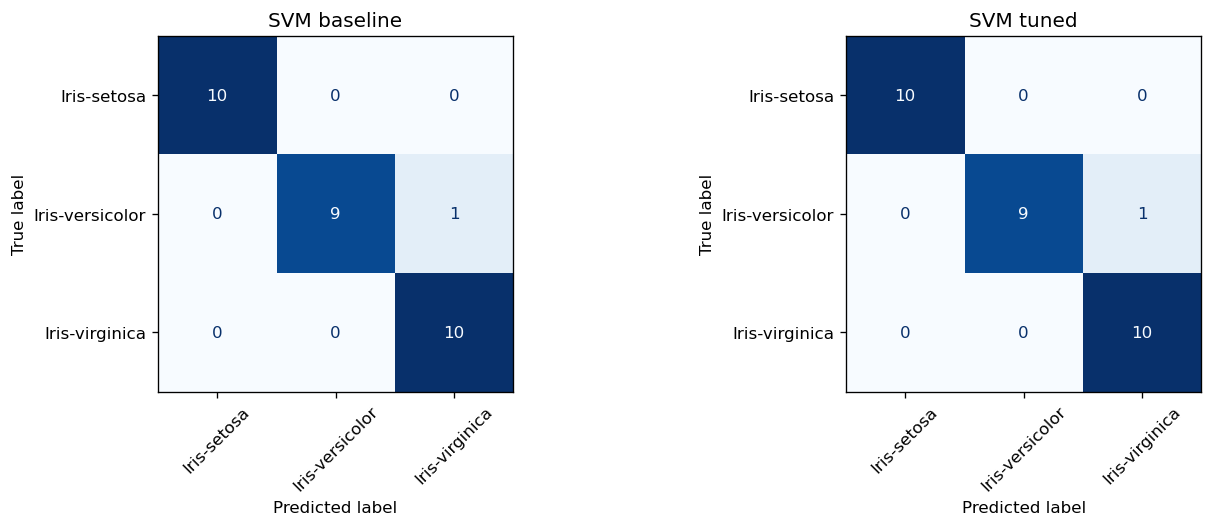

In [6]:
# Danh gia mot lan sau khi chot cau hinh bang CV.
models = {'SVM baseline': baseline, 'SVM tuned': best_svm}
cv_scores = {'SVM baseline': baseline_cv_scores.mean(), 'SVM tuned': search.best_score_}
labels = sorted(pd.unique(y))
is_binary = len(labels) == 2
minority_label = y_train.value_counts().idxmin() if is_binary else None
records, predictions, decision_scores = [], {}, {}

for name, model in models.items():
    pred = model.predict(X_test)
    predictions[name] = pred
    row = {
        'Model': name, 'Train accuracy': model.score(X_train, y_train),
        'CV score': cv_scores[name], 'Test accuracy': accuracy_score(y_test, pred),
        'Test balanced accuracy': balanced_accuracy_score(y_test, pred),
        'Test precision macro': precision_score(y_test, pred, average='macro', zero_division=0),
        'Test recall macro': recall_score(y_test, pred, average='macro', zero_division=0),
        'Test F1 macro': f1_score(y_test, pred, average='macro', zero_division=0)
    }
    if is_binary:
        scores = model.decision_function(X_test)
        decision_scores[name] = scores
        minority_scores = scores if minority_label == model.classes_[1] else -scores
        row['Test ROC AUC (class 1)'] = roc_auc_score(y_test, scores)
        row['Minority label'] = minority_label
        row['Minority precision'] = precision_score(y_test, pred, pos_label=minority_label, zero_division=0)
        row['Minority recall'] = recall_score(y_test, pred, pos_label=minority_label, zero_division=0)
        row['Minority average precision'] = average_precision_score((y_test==minority_label).astype(int), minority_scores)
    records.append(row)
    print('\n' + name)
    print(classification_report(y_test, pred, labels=labels, target_names=CLASS_NAMES, zero_division=0))

comparison_df = pd.DataFrame(records).set_index('Model')
display(comparison_df.round(4))
majority_baseline = y_test.value_counts(normalize=True).max()
print('Accuracy neu luon doan lop pho bien:', round(majority_baseline, 4))

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5 if len(labels)<=3 else 5))
for ax, name in zip(axs, models):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions[name], labels=labels, display_labels=CLASS_NAMES,
        cmap='Blues', colorbar=False, ax=ax, xticks_rotation=45 if len(labels)==3 else 0
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

if is_binary:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for name, model in models.items():
        scores = decision_scores[name]
        RocCurveDisplay.from_predictions(y_test, scores, name=name, ax=axes[0])
        minority_scores = scores if minority_label==model.classes_[1] else -scores
        PrecisionRecallDisplay.from_predictions(
            (y_test==minority_label).astype(int), minority_scores, name=name, ax=axes[1]
        )
    axes[0].plot([0, 1], [0, 1], '--', color='gray')
    axes[0].set_title('Test ROC (positive class = 1)')
    axes[1].set_title(f'Test precision-recall (class {minority_label})')
    plt.tight_layout()
    plt.show()

### Bước 5. Quan sát vector hỗ trợ

SVC hỗ trợ support_, n_support_. Chỉ số support_ tương ứng vị trí trong X_train. Hình là phép chiếu lên hai số đo cánh hoa, không phải ranh giới đầy đủ của mô hình dùng 4 đặc trưng.

So support vectors theo lop: {'Iris-setosa': np.int32(2), 'Iris-versicolor': np.int32(7), 'Iris-virginica': np.int32(7)}


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
43,5.0,3.5,1.6,0.6
41,4.5,2.3,1.3,0.3
98,5.1,2.5,3.0,1.1
84,5.4,3.0,4.5,1.5
72,6.3,2.5,4.9,1.5


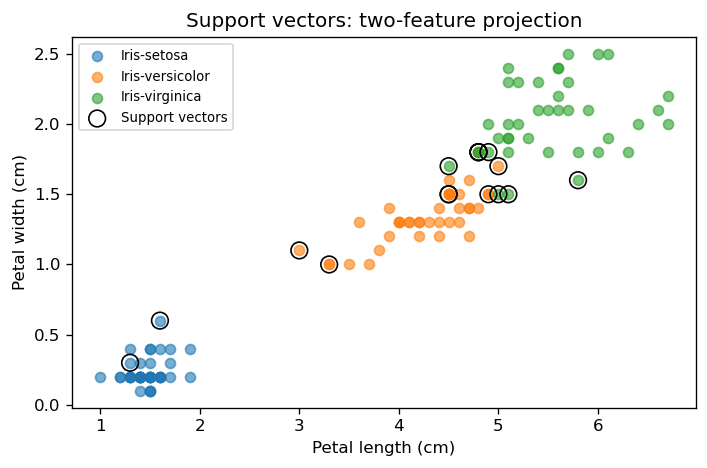

In [7]:
svc=best_svm.named_steps['svc']
print('So support vectors theo lop:',dict(zip(svc.classes_,svc.n_support_)))
support_rows=X_train.iloc[svc.support_]
display(support_rows.head())
fig,ax=plt.subplots(figsize=(6,4))
for label in CLASS_NAMES:
    rows=y_train==label
    ax.scatter(X_train.loc[rows,'PetalLengthCm'],X_train.loc[rows,'PetalWidthCm'],label=label,alpha=0.6)
ax.scatter(support_rows['PetalLengthCm'],support_rows['PetalWidthCm'],s=100,
           facecolors='none',edgecolors='black',label='Support vectors')
ax.set(xlabel='Petal length (cm)',ylabel='Petal width (cm)',title='Support vectors: two-feature projection')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Nhận xét và lưu kết quả

In [8]:
best_row = cv_results_df.loc[search.best_index_]
gap = float(best_row['mean_train_score'] - best_row['mean_test_score'])
tuned = comparison_df.loc['SVM tuned']
acc = tuned['Test accuracy']
f1 = tuned['Test F1 macro']
balanced_acc = tuned['Test balanced accuracy']
notes = '\n\n'.join([
    '### Nhận xét kết quả',
    f'- Train **{len(X_train):,} mẫu**, test **{len(X_test):,} mẫu**. Siêu tham số được chọn bằng **{SCORING}**, 4-fold CV trên train.',
    f'- Tham số chọn trong lưới: **{search.best_params_}**. Điểm CV **{search.best_score_:.4f}**; chênh lệch train - validation tại cấu hình này **{gap:.4f}**.',
    f'- SVM sau tìm kiếm đạt test accuracy **{acc:.4f}**, balanced accuracy **{balanced_acc:.4f}**, F1-macro **{f1:.4f}**.',
    f'- Nếu luôn đoán lớp phổ biến, accuracy là **{majority_baseline:.4f}**. Cần đọc thêm confusion matrix và chỉ số từng lớp để tránh đánh giá sai khi nhãn mất cân bằng.',
    '- Khoảng cách điểm train/validation là dấu hiệu tham khảo về quá khớp, không đo trực tiếp bias/variance. Cấu hình được chọn chỉ tốt nhất trong lưới đã thử.',
    '- Pipeline chỉ fit scaler/imputer/encoder trên phần train của từng fold. Không chọn lại siêu tham số theo test. SVC/LinearSVC dùng decision_function khi đánh giá ROC AUC; đây là điểm quyết định, không phải xác suất đã hiệu chỉnh.'
])
if is_binary:
    minority_count = int((y_test==minority_label).sum())
    precision_minority = tuned['Minority precision']
    recall_minority = tuned['Minority recall']
    notes += f'\n\n- Lớp ít mẫu là **{minority_label}**, có **{minority_count} mẫu test**. Precision **{precision_minority:.4f}**, recall **{recall_minority:.4f}**.'
display(Markdown(notes))

RESULTS_DIR = LAB_DIR / 'ket_qua' / RESULT_SLUG
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
comparison_df.to_csv(RESULTS_DIR/'so_sanh_mo_hinh.csv', encoding='utf-8-sig')
cv_results_df.to_csv(RESULTS_DIR/'cv_results.csv', index=False, encoding='utf-8-sig')
prediction_table = pd.DataFrame({'row_index':X_test.index, 'actual':y_test.to_numpy(),
    'baseline_prediction':predictions['SVM baseline'], 'tuned_prediction':predictions['SVM tuned']})
if is_binary:
    prediction_table['baseline_score']=decision_scores['SVM baseline']
    prediction_table['tuned_score']=decision_scores['SVM tuned']
prediction_table.to_csv(RESULTS_DIR/'du_doan_test.csv',index=False,encoding='utf-8-sig')
(RESULTS_DIR/'nhan_xet.md').write_text(notes,encoding='utf-8')
print('Ket qua da luu:',RESULTS_DIR)

### Nhận xét kết quả

- Train **120 mẫu**, test **30 mẫu**. Siêu tham số được chọn bằng **accuracy**, 4-fold CV trên train.

- Tham số chọn trong lưới: **{'svc__C': 10, 'svc__kernel': 'linear'}**. Điểm CV **0.9750**; chênh lệch train - validation tại cấu hình này **0.0083**.

- SVM sau tìm kiếm đạt test accuracy **0.9667**, balanced accuracy **0.9667**, F1-macro **0.9666**.

- Nếu luôn đoán lớp phổ biến, accuracy là **0.3333**. Cần đọc thêm confusion matrix và chỉ số từng lớp để tránh đánh giá sai khi nhãn mất cân bằng.

- Khoảng cách điểm train/validation là dấu hiệu tham khảo về quá khớp, không đo trực tiếp bias/variance. Cấu hình được chọn chỉ tốt nhất trong lưới đã thử.

- Pipeline chỉ fit scaler/imputer/encoder trên phần train của từng fold. Không chọn lại siêu tham số theo test. SVC/LinearSVC dùng decision_function khi đánh giá ROC AUC; đây là điểm quyết định, không phải xác suất đã hiệu chỉnh.

Ket qua da luu: D:\SGU_HocMay_2026-2027\Lab05\2.2. Giai_Thuat2\ket_qua\Bai_mau_Iris


### Diễn giải cho lần chạy đã lưu

Kernel linear với C=10 được chọn bằng CV. Accuracy test của baseline và cấu hình sau tìm kiếm đều là 96,67% (29/30 mẫu); tối ưu trên CV không bảo đảm điểm test tăng. Hình vector hỗ trợ chỉ chiếu dữ liệu 4 chiều xuống hai số đo cánh hoa.

## Tài liệu kỹ thuật

- [Scikit-learn - SVM](https://scikit-learn.org/1.7/modules/svm.html)
- [SVC](https://scikit-learn.org/1.7/modules/generated/sklearn.svm.SVC.html)
- [LinearSVC](https://scikit-learn.org/1.7/modules/generated/sklearn.svm.LinearSVC.html)
- [GridSearchCV](https://scikit-learn.org/1.7/modules/generated/sklearn.model_selection.GridSearchCV.html)